## EDA
###

In [1]:
#Install the required libraries
!pip install numpy
!pip install pandas
!pip install matplotlib
!pip install openpyxl
!pip install sklearn

  Using cached sklearn-0.0.post12.tar.gz (2.6 kB)
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'error'


  error: subprocess-exited-with-error
  
  × Getting requirements to build wheel did not run successfully.
  │ exit code: 1
  ╰─> [15 lines of output]
      The 'sklearn' PyPI package is deprecated, use 'scikit-learn'
      rather than 'sklearn' for pip commands.
      
      Here is how to fix this error in the main use cases:
      - use 'pip install scikit-learn' rather than 'pip install sklearn'
      - replace 'sklearn' by 'scikit-learn' in your pip requirements files
        (requirements.txt, setup.py, setup.cfg, Pipfile, etc ...)
      - if the 'sklearn' package is used by one of your dependencies,
        it would be great if you take some time to track which package uses
        'sklearn' instead of 'scikit-learn' and report it to their issue tracker
      - as a last resort, set the environment variable
        SKLEARN_ALLOW_DEPRECATED_SKLEARN_PACKAGE_INSTALL=True to avoid this error
      
      More information is available at
      https://github.com/scikit-learn/sklearn-

In [2]:
import seaborn as sns #Library for ploting
import numpy as np #Importing the library for manipulating arrays, matrices and maths
import pandas as pd #Importing the library for working with data structures (clearing it, chek it, manipulate)
import matplotlib.pyplot as plt #Library for ploting

In [3]:
cl18 = pd.read_excel(r"C:\Users\JBRRe\OneDrive\Documentos\Visual_EXPCODES\Kaggle_CosasSerias_DataScience\Datos\PM2.5_SEMADET\Cleared_Data\Clear18.xlsx") #Read the path where the excel is located
cl19 = pd.read_excel(r"C:\Users\JBRRe\OneDrive\Documentos\Visual_EXPCODES\Kaggle_CosasSerias_DataScience\Datos\PM2.5_SEMADET\Cleared_Data\Clear19.xlsx") #Read the path where the excel is located
cl20 = pd.read_excel(r"C:\Users\JBRRe\OneDrive\Documentos\Visual_EXPCODES\Kaggle_CosasSerias_DataScience\Datos\PM2.5_SEMADET\Cleared_Data\Clear20.xlsx") #Read the path where the excel is located
cl21 = pd.read_excel(r"C:\Users\JBRRe\OneDrive\Documentos\Visual_EXPCODES\Kaggle_CosasSerias_DataScience\Datos\PM2.5_SEMADET\Cleared_Data\Clear21.xlsx") #Read the path where the excel is located
cl22 = pd.read_excel(r"C:\Users\JBRRe\OneDrive\Documentos\Visual_EXPCODES\Kaggle_CosasSerias_DataScience\Datos\PM2.5_SEMADET\Cleared_Data\Clear22.xlsx") #Read the path where the excel is located
cl23 = pd.read_excel(r"C:\Users\JBRRe\OneDrive\Documentos\Visual_EXPCODES\Kaggle_CosasSerias_DataScience\Datos\PM2.5_SEMADET\Cleared_Data\Clear23.xlsx") #Read the path where the excel is located

In [4]:
pd.set_option('display.max_columns', 22) #Set the max number of columns/rows to be displayed 
pd.set_option('display.max_rows', 100)
dfs = [cl18, cl19, cl20, cl21, cl22, cl23]#List our dataframes
#List the columns to drop
Cols_Und4 = ['dia ','mes ','NO2','ATM','SO2','CO','PP','ET'] #WD, RH, PM10 n' O3 have to wait finishing EDA to decide if must be included or droped before modeling
#Iterate the dataframes list looking for those columns to drop, if ain´t just goes for the next df
for df in dfs:
        df.drop(columns=Cols_Und4, inplace=True, errors="ignore")

Model_Data = pd.concat([cl18, cl19, cl20, cl21, cl22, cl23], axis=0, ignore_index=True) #Concat all datasets into a single one, had already drop those columns that only appear on 3 years or less
Model_Data.head()

,STATION,DATE,HOUR,O3,PM10,PM2.5,IT,WS,WD,RH
0,CEN,2018-06-01 00:00:00,0,0.023,51.0,39,23.243846,4.12,184.64,NaN
1,CEN,2018-06-01 01:00:00,1,0.022,46.0,34,23.243846,4.25,234.47,NaN
2,CEN,2018-06-01 02:00:00,2,0.021,46.0,32,23.243846,3.86,303.91,NaN
3,CEN,2018-06-01 03:00:00,3,0.018,39.0,36,23.243846,3.83,302.17,NaN
4,CEN,2018-06-01 04:00:00,4,0.018,42.0,39,23.243846,4.30,293.90,NaN


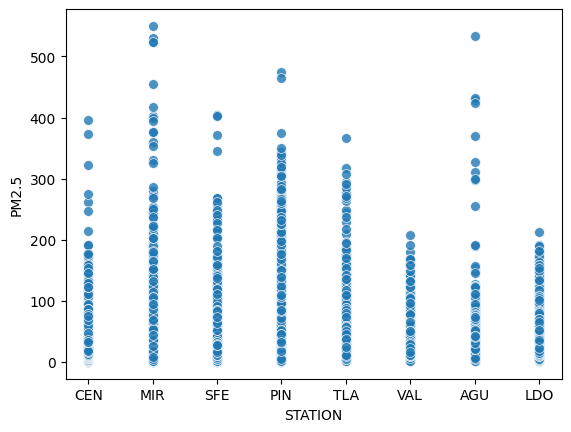

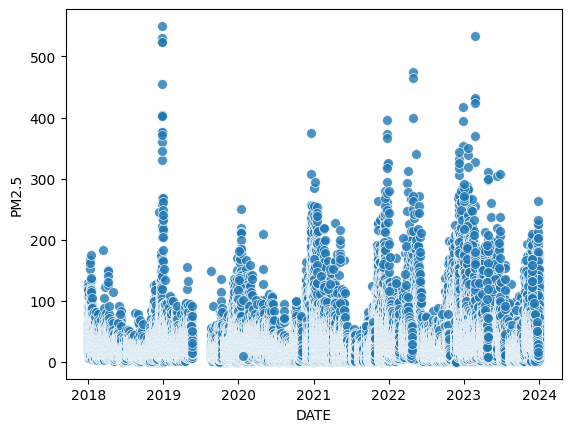

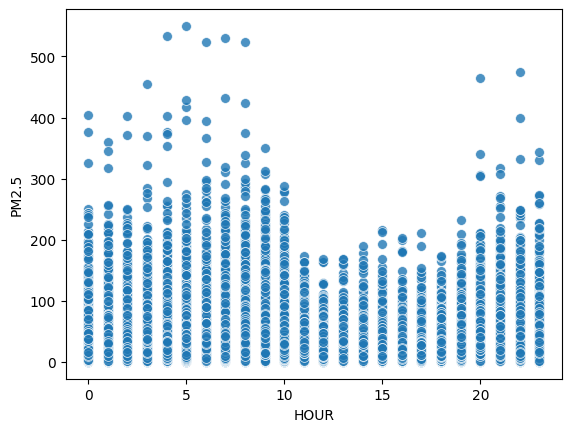

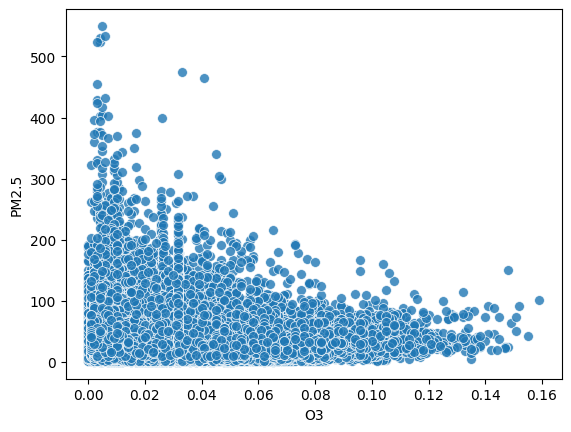

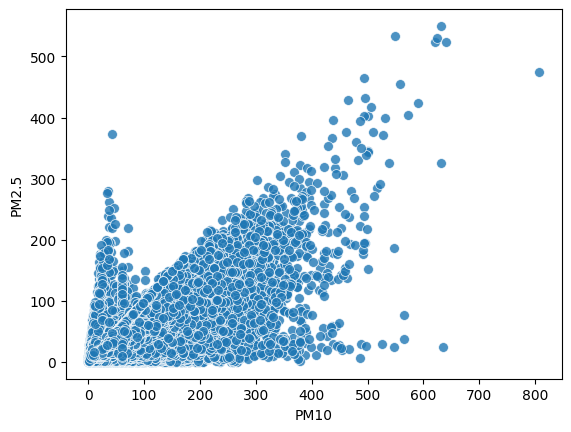

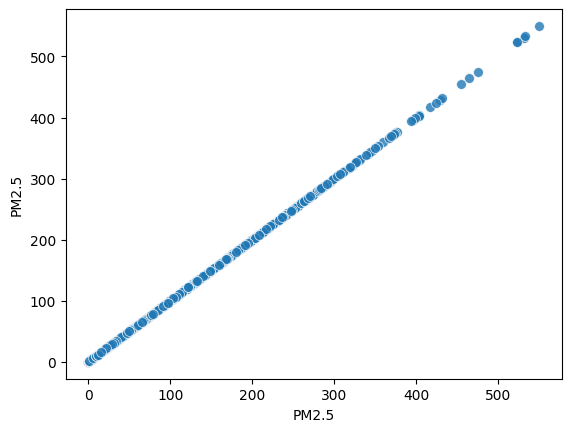

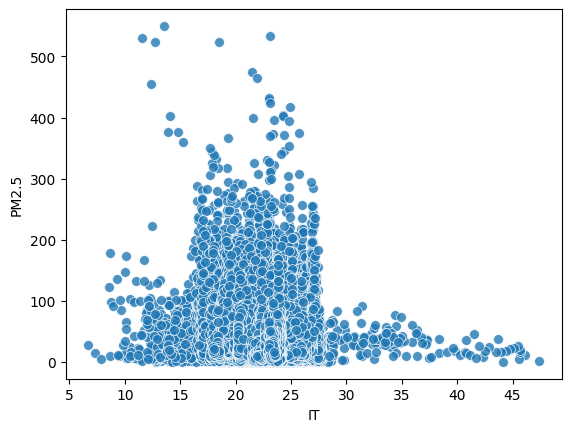

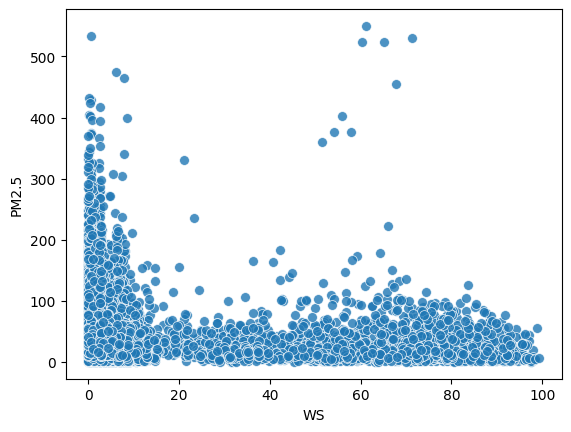

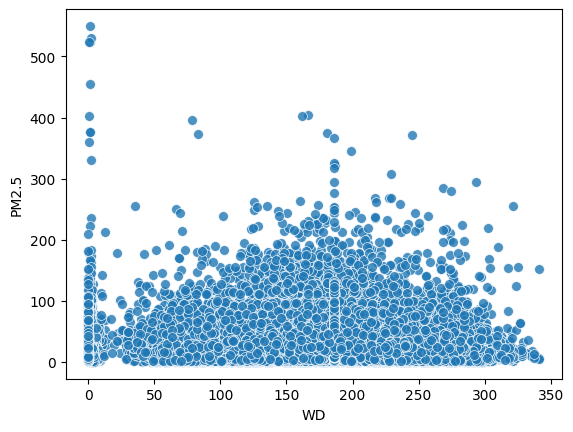

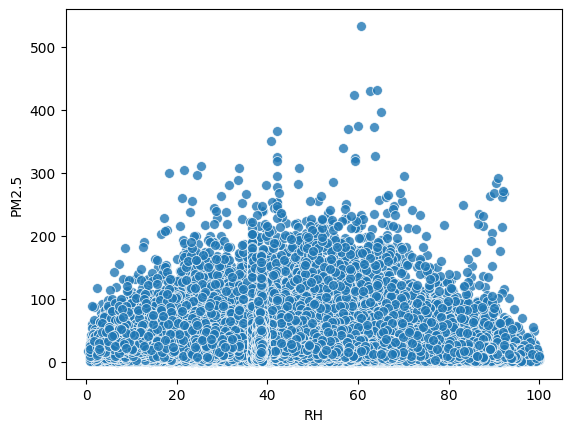

In [5]:
Columns = list(Model_Data.columns) #Created a list with just column names
for Column in Columns:
    sns.scatterplot(data=Model_Data, x=Column, y="PM2.5", alpha=.8, s=50)
    plt.show()
#This for creates a scatterplot for each column against PM2.5 to visually check patterns, principally correlations    


##### Alrigt, basicly we got highly dispersed data, Some of the variables presents a slightly negative correlation, due dispersion is not clear to ensure if variables are correlated enough to formulate an hypotesis except for PM10 we can see a visible correlation. So I runed the measure of each correlation technique against PM2.5, in case of non lineal behavior.

In [6]:
%pip install scipy
def cor(me):#Function for calculate each correlation type
  corr_pm25 = (
      Model_Data.corr(method=me, numeric_only=True)["PM2.5"]
        .sort_values(ascending=False)
  )
  print(corr_pm25)

cor("spearman")#Monotonous and non lineal
cor("kendall")#
cor("pearson")#Lineal Correlations
#We calculate the correlation by three coefficients against PM2.5, (to check lineal and non-lineal relations)

Note: you may need to restart the kernel to use updated packages.
PM2.5    1.000000
PM10     0.671285
HOUR    -0.010193
O3      -0.042206
WD      -0.085000
RH      -0.101145
IT      -0.123558
WS      -0.154070
Name: PM2.5, dtype: float64
PM2.5    1.000000
PM10     0.505172
HOUR    -0.006885
O3      -0.027867
WD      -0.057183
RH      -0.068769
IT      -0.085720
WS      -0.105040
Name: PM2.5, dtype: float64
PM2.5    1.000000
PM10     0.731328
HOUR    -0.029600
WS      -0.037775
RH      -0.066016
WD      -0.070793
O3      -0.072024
IT      -0.144034
Name: PM2.5, dtype: float64


##### So we got almost similar coefficients, that means the issue isn´t just the behavior is non lineal, kendall and pearson are for monotonous non lineal relation, as long it increases/decreases consistently there are detection, but it may be non-monotonous

##### Other thing, we got cyclic variables that could affect PM2.5 but are in the wrong format, must do a cyclic encoding using sin and cos

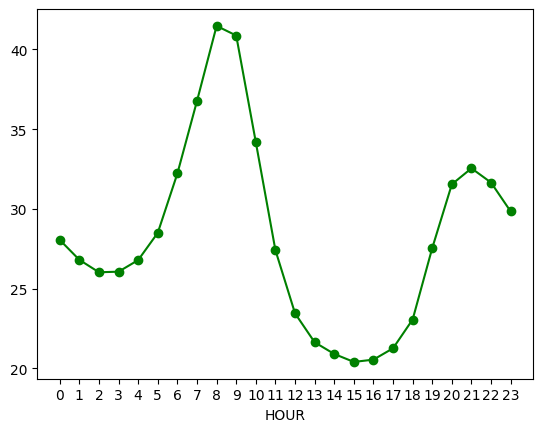

In [7]:
#WD is in degrees, 0 is similar to 359, same as hours 0 with 23. So similar data is interpreted as whole different values
Model_Data["Hour_sin"] = np.sin(2*np.pi*Model_Data["HOUR"]/24)
Model_Data["Hour_cos"] = np.cos(2*np.pi*Model_Data["HOUR"]/24)
#Added another due the graph sape, 2 peaks 2 valleys
Model_Data['Hour_sin2'] = np.sin(2 * (2 * np.pi * df['HOUR'] / 24))
Model_Data['Hour_cos2'] = np.cos(2 * (2 * np.pi * df['HOUR'] / 24))
#Tracks each value in a circle, each one is unique due a combination between sin n' cos (24-hours 360-degrees)
Model_Data["WD_sin"] = np.sin(2*np.pi*Model_Data["WD"]/360)
Model_Data["WD_cos"] = np.cos(2*np.pi*Model_Data["WD"]/360)

avg_hrs = Model_Data.groupby('HOUR')['PM2.5'].mean()#Group the average PM2.5 by hour
avg_hrs.plot(kind='line', marker='o', color='green')#Pandas method for ploting

plt.xticks(avg_hrs.index)#X axis divided by our index
plt.show()

##### The table shows that the PM2.5 concentration increases during peak hours of urban activity, particularly during the morning and evening commuting periods.

WD_bin
S     21.225357
W     19.835234
SW    18.080636
SE    15.431420
E     12.232480
N      7.363284
NE     3.387201
NW     2.444388
Name: proportion, dtype: float64


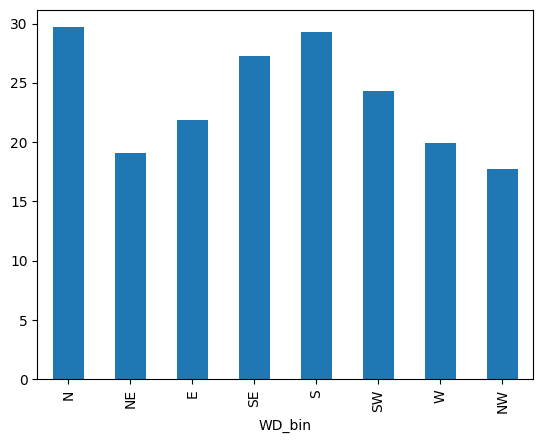

In [ ]:
def deg_to_cardinal(deg): #Func for perfectly classify degrees into bins
    if pd.isna(deg): #Check nan values
        return np.nan
    dirs = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']#Wind directions
    idx = int((deg + 22.5) // 45) % 8#Perfect cut
    return dirs[idx]

Model_Data['WD_bin'] = Model_Data['WD'].apply(deg_to_cardinal)# Aply our function to our data

wd_avg = Model_Data.groupby('WD_bin')['PM2.5'].mean()

# Reordenar para que el gráfico salga en orden cardinal, no alfabético
order = ['N', 'NE', 'E', 'SE', 'S', 'SW', 'W', 'NW']
wd_avg = wd_avg.reindex(order)

wd_avg.plot(kind='bar')


##### The following table summarizes the relationship between PM2.5 concentration and wind direction. The highest PM2.5 levels are associated with northerly and southerly wind directions.

##### We evaluate the relationship between wind speed (WS) and PM2.5 concentration, since such a relationship is physically expected despite the low correlation coefficients.

<Axes: xlabel='HOUR', ylabel='PM2.5'>

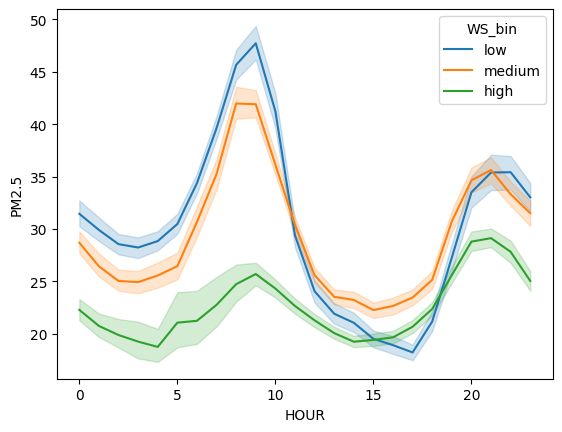

In [9]:
Model_Data['WS_bin'] = pd.qcut(Model_Data['WS'], q=3, labels=['low', 'medium', 'high'])#Create a new clumn that is a clasification of each third of our column
sns.lineplot(data=Model_Data, x='HOUR', y='PM2.5', hue='WS_bin', estimator='mean')#hue creates a line for each category in WS_bin, estimator obtains the avg for each conv of hour and wind

##### The data analysis reveals an inverse relationship between wind speed and PM2.5 concentration. As wind speed decreases, PM2.5 concentration tends to increase, likely due to reduced pollutant dispersion. Conversely, higher wind speeds promote pollutant dispersion, resulting in lower PM2.5 concentrations.

##### O3 Analysis

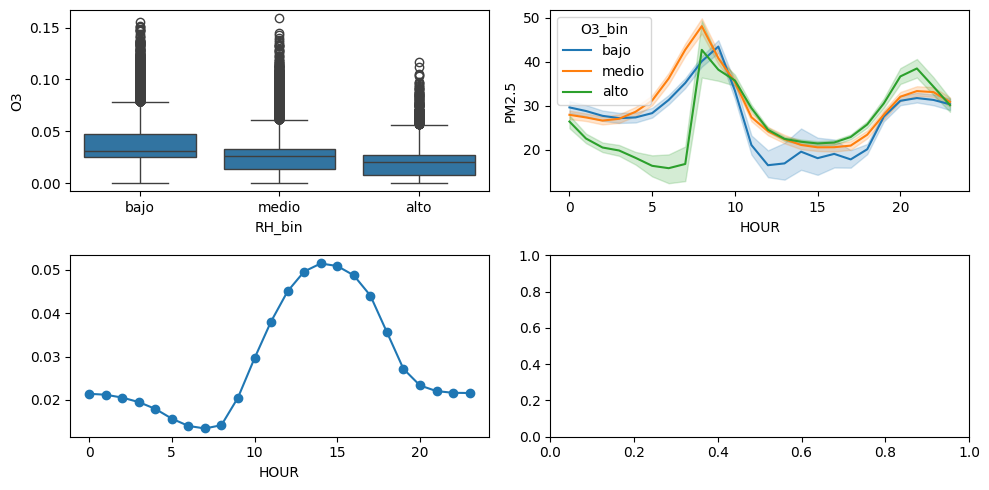

O3_bin,bajo,medio,alto
HOUR,,,
0,2200,2367,715
1,2164,2412,625
2,2355,2459,535
3,2587,2342,402
4,2938,2151,271
5,3287,1998,123
6,3529,1872,39
7,3627,1841,27
8,3735,1545,152


In [10]:
fig, axes = plt.subplots(2, 2, figsize=(10, 5)) #Create a 2x2 grid of subplots to compare RH, O3 and PM2.5 relationships

# Boxplot
Model_Data['RH_bin'] = pd.qcut(Model_Data['RH'], q=3, labels=['bajo', 'medio', 'alto']) #Bin RH into 3 equal-frequency groups (low/med/high) to explore its relation with O3
Model_Data['O3_bin'] = pd.qcut(Model_Data['O3'], q=3, labels=['bajo', 'medio', 'alto'])

sns.boxplot(
    data=Model_Data,
    x='RH_bin',
    y='O3',
    ax=axes[0, 0]
) #Boxplot of O3 distribution across RH bins, top-left subplot

o3_avg = Model_Data.groupby('HOUR')['O3'].mean() #Average O3 for each hour, to see the diurnal cycle

o3_avg.plot(
    kind='line',
    marker='o',
    ax=axes[1, 0]
) #Line plot of O3's hourly cycle, bottom-left subplot

sns.lineplot(
    data=Model_Data,
    x='HOUR',
    y='PM2.5',
    hue='O3_bin', #Bin O3 into 3 levels on the fly (not saved as a column) to color-split the PM2.5 lines
    estimator='mean',
    ax=axes[0, 1]
) #PM2.5 hourly average, one line per O3 level, top-right subplot

plt.tight_layout() #Adjust spacing so subplots don't overlap
plt.show()

pd.crosstab(Model_Data['HOUR'], Model_Data['O3_bin']) #Cross-tab of HOUR vs O3_bin to check sample counts per hour/bin combo


##### We can observe a relationship between relative humidity (RH) and O₃ concentrations in the boxplot. As expected, higher RH is generally associated with cloudier or rainy conditions, which reduce solar radiation. Since ozone formation is largely driven by sunlight through photochemical reactions involving NOₓ and volatile organic compounds (VOCs), O₃ concentrations tend to be lower when RH is high.
##### This observation is supported by the blue line showing the hourly average O₃ concentration. O₃ reaches its peak around 1:00 p.m. In Guadalajara and the surrounding metropolitan area, the period between approximately 11:00 a.m. and 3:00 p.m. usually receives the highest solar radiation, which favors ozone formation.
##### The third plot shows the hourly average PM2.5 concentration grouped by O₃ categories. Our interpretation is that although ozone formation mainly depends on solar radiation, it also requires precursor pollutants such as nitrogen oxides (NOₓ), which are largely emitted by motor vehicles. These emissions also contribute, directly and indirectly, to PM2.5 formation. As solar radiation increases throughout the day, photochemical reactions gradually produce more ozone. This process is not instantaneous; therefore, O₃ accumulates over several hours. During the early morning, PM2.5 concentrations are relatively high while O₃ remains low because solar radiation is still insufficient to drive significant ozone formation. Later in the day, as O₃ approaches its peak, the second PM2.5 peak also becomes more pronounced. This should not be interpreted as a causal relationship between PM2.5 and O₃; instead, both pollutants are influenced by common factors, particularly traffic emissions and daytime photochemistry.
##### Note: An important feature of this graph is the behavior observed during the first seven hours of the day. Although the high O₃ category appears to have lower PM2.5 values than the other categories during this period, this is a methodological artifact rather than a real environmental pattern.
##### The O₃ data were divided into three categories using the qcut() method before calculating the hourly averages. Because qcut() assigns observations according to the overall distribution of O₃ values in the complete dataset, the categories are defined globally rather than independently for each hour. As a result, observations belonging to the high O₃ category may still have relatively low O₃ values during the early morning compared with observations recorded later in the day. Consequently, the hourly average for the high O₃ category appears lower during those hours, producing the apparent inconsistency in the graph.

<Axes: xlabel='HOUR', ylabel='PM2.5'>

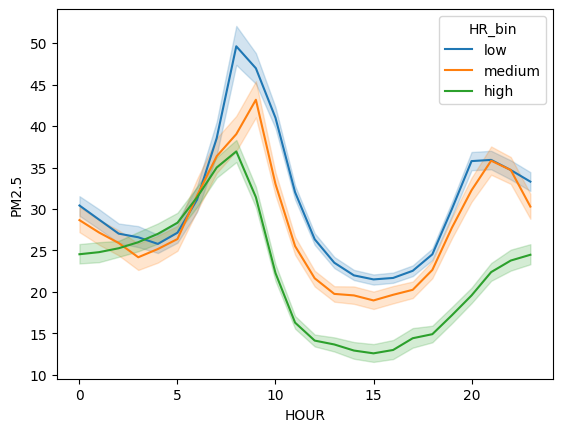

In [11]:
Model_Data['HR_bin'] = pd.qcut(Model_Data['RH'], q=3, labels=['low', 'medium', 'high'])#Create a new clumn that is a clasification of each third of our column
sns.lineplot(data=Model_Data, x='HOUR', y='PM2.5', hue='HR_bin', estimator='mean')#hue creates a line for each category in HR_bin, estimator obtains the avg for each conv of hour and wind

##### The pattern is similar: higher relative humidity is associated with lower PM2.5 concentrations. Relative humidity itself does not necessarily remove airborne particles. Instead, high Relative humidity (RH) is often associated with rainy conditions or stronger atmospheric mixing, which can reduce PM2.5 concentrations through wet deposition and dispersion.

<Axes: xlabel='HOUR'>

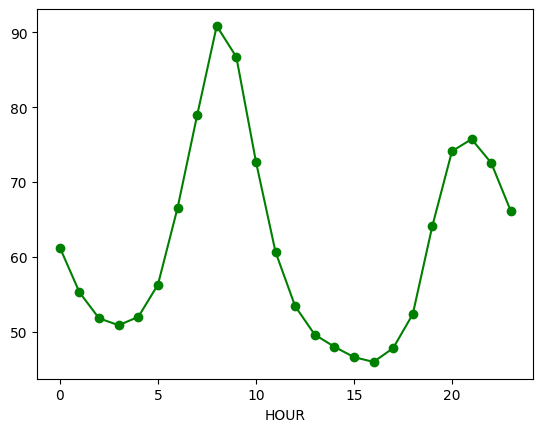

In [12]:
avg_hrs10 = Model_Data.groupby('HOUR')['PM10'].mean()#Group the average PM10 by hour
avg_hrs10.plot(kind='line', marker='o', color='green')#Pandas method for ploting

##### The hourly average PM10 concentration shows a clear bimodal pattern throughout the day. Similar as the PM2.5 pattern, this displays an example about it´s correlation with PM2.5

PM10_bin,low,medium,high
HOUR,,,
0,1748,1675,1432
1,2025,1555,1141
2,2352,1490,1116
3,2366,1462,1097
4,2336,1449,1163
5,2123,1461,1400
6,1724,1461,1833
7,1409,1348,2308
8,1176,1177,2642


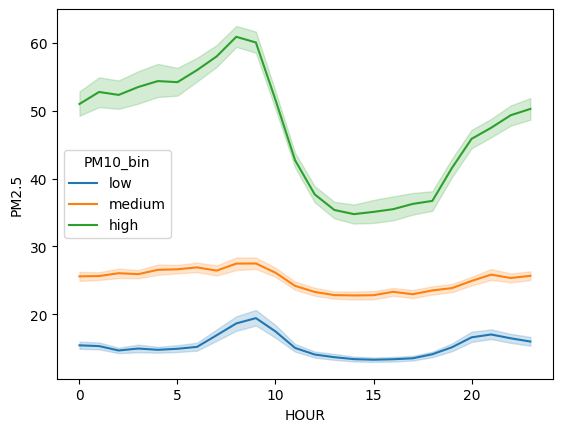

In [13]:
Model_Data['PM10_bin'] = pd.qcut(Model_Data['PM10'], q=3, labels=['low', 'medium', 'high'])#Create a new clumn that is a clasification of each third of our column
sns.lineplot(data=Model_Data, x='HOUR', y='PM2.5', hue='PM10_bin', estimator='mean')#hue creates a line for each category in PM10_bin, estimator obtains the avg for each conv of hour and wind

pd.crosstab(Model_Data['HOUR'], Model_Data['PM10_bin'])

##### This plot shows how the hourly average PM2.5 concentration changes according to the PM10 category. As expected, higher PM10 levels are associated with higher PM2.5 concentrations.

##### One interesting feature is that all three categories follow almost the same daily pattern. PM2.5 reaches its highest concentrations during the morning, decreases throughout the afternoon, and rises again during the evening. The main difference is the concentration level rather than the shape of the curve.

##### This suggests that PM2.5 and PM10 are affected by similar sources and atmospheric conditions. Since PM2.5 particles are part of PM10, it is expected that both pollutants increase and decrease together during the day.

<Axes: xlabel='STATION'>

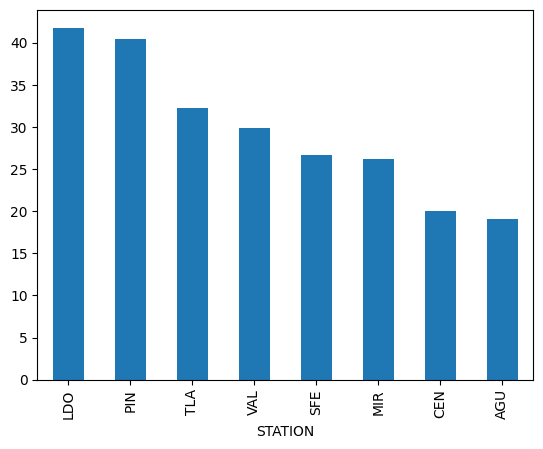

In [14]:
st_avg = Model_Data.groupby('STATION')['PM2.5'].mean().sort_values(ascending=False) #Average PM2.5 per station, sorted to see which stations pollute more
st_avg.plot(kind='bar')


##### We are going to study the three most polluted stations

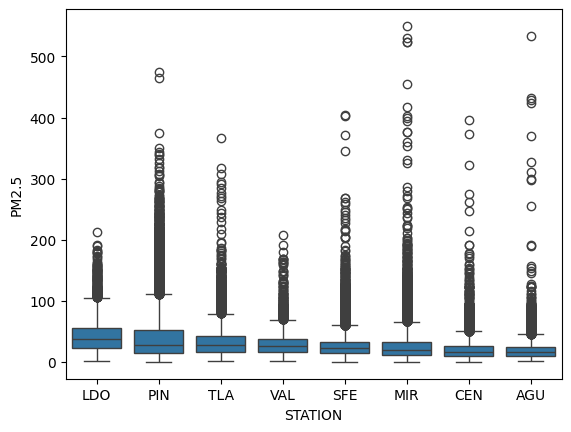

WD_bin
S     21.225357
W     19.835234
SW    18.080636
SE    15.431420
E     12.232480
N      7.363284
NE     3.387201
NW     2.444388
Name: proportion, dtype: float64


In [ ]:

sns.boxplot(data=Model_Data, x='STATION', y='PM2.5', order=st_avg.index) #Cheking outliers and different measures besides average
plt.show()
per = Model_Data['WD_bin'].value_counts(normalize=True)*100#Obtaining percentage 
print(per)

##### Atmospheric drainage refers to the process by which air pollutants are transported, dispersed, or removed from a region through atmospheric and meteorological processes. The effectiveness of this process depends on factors such as wind speed, wind direction, atmospheric stability, humidity, and precipitation. In addition to meteorological conditions, pollutant concentrations are influenced by anthropogenic factors, including industrial activity, urbanization, and traffic emissions, as well as temporal factors such as the season of the year and peak traffic hours. Together, these factors determine the atmosphere's ability to disperse or accumulate pollutants within metropolitan areas.

##### Due to urban factors, industrial activity, geographic ubication and atmospheric drainage LOMA DORASA, LAS PINTAS, and TLAQUEPAQUE are the most polluted stations, for example LAS PINTAS is part of an important industrial corridor, TLAQUEPAQUE is a valley with strong urban activity and bussines related to burnig things, same as LDO, and the wind directions are  likely towards their ubication

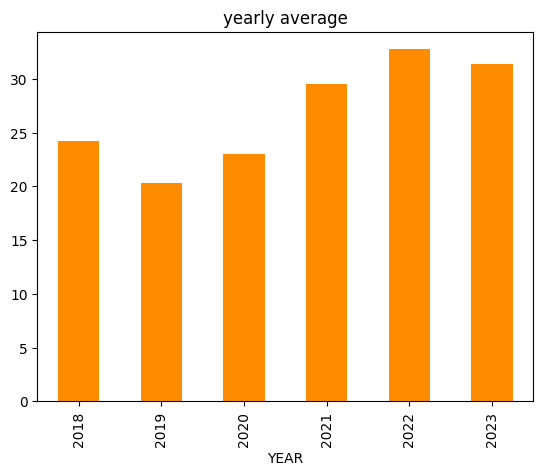

WD_bin
S     21.225357
W     19.835234
SW    18.080636
SE    15.431420
E     12.232480
N      7.363284
NE     3.387201
NW     2.444388
Name: proportion, dtype: float64


In [ ]:
# DATE decomposition
Model_Data['MONTH'] = Model_Data['DATE'].dt.month #Extract month from DATE to check seasonality
Model_Data['YEAR'] = Model_Data['DATE'].dt.year #Extract year from DATE to check interannual trend

# function to calculate the average of a variable per month to check seasonality
def Gr(Vari):
    month_avg = Model_Data.groupby('MONTH')[Vari].mean()#Group by month and calculate the average
    month_avg.plot(kind='line', marker='o', color='darkorange')
    plt.xticks(month_avg.index)
    plt.title(f'{Vari} monthly average')
    plt.show()

# *Year
year_avg = Model_Data.groupby('YEAR')['PM2.5'].mean()
year_avg.plot(kind='bar', color='darkorange')
plt.title('yearly average')
plt.show()

##### The tendence is clear, the pollution is likely to increase with some exceptions, during 2018 the vakues may seem a bit low, that is because during 2018 only three stations could measure PM2.5, and 2019 had a strong data loss due cleaning process. Despite having less stations 2018 had an average PM2.5 higher tham 2020, during pandemic, the human activity droped importantly, we have seen trafic is a key factor for PM2.5 creation.

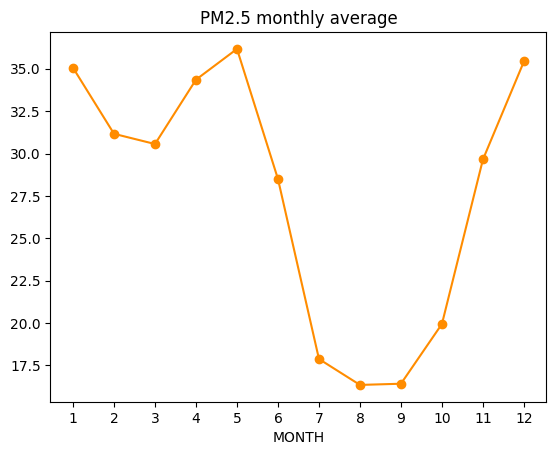

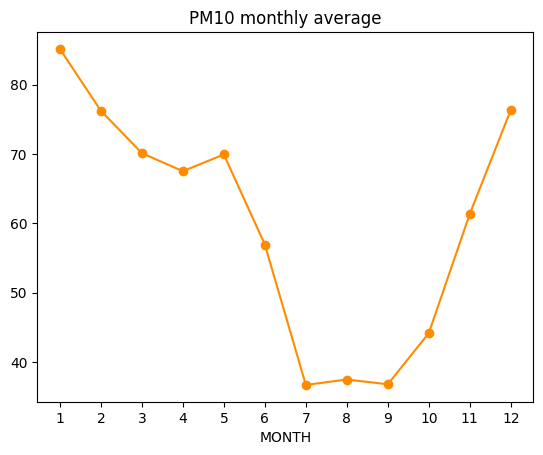

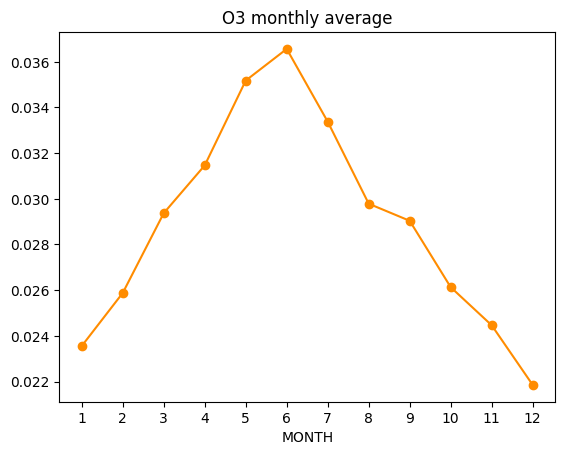

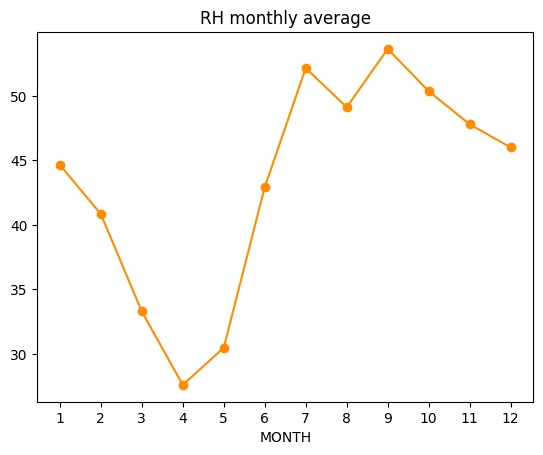

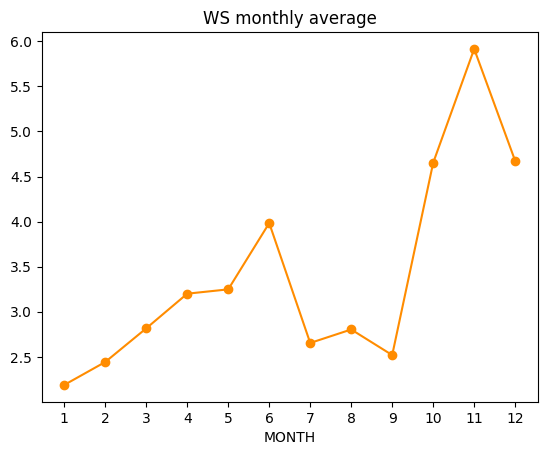

In [17]:

Gr("PM2.5")
Gr("PM10")
Gr("O3")
Gr("RH")
Gr("WS")

In [ ]:
mod_men = Model_Data.groupby("MONTH")["WD_bin"].agg(lambda x: x.mode().iloc[0])

print(mod_men)

MONTH
1      S
2      S
3      W
4      W
5      W
6      S
7     SE
8      E
9      E
10     S
11     S
12     S
Name: WD_bin, dtype: object


##### As we have seen, Relative Humidity, Wind Direction and Wind Speed affects directly the PM2.5 Behaviour. But we think the relation is likely the interaction between each factor more than onse single factor.
##### For example let´s analyze the PM2.5 the lowest points are between july to spetember, that coincides with the rainy season, when it´s raining, the humidity is higher, we´ve seen an inverse relationship between humidity and RH, but then PM2.5 increases again for the rest of the year, very interesting because WS and RH don´t decrease at all, even when is WS´s peak run. So that makes me thing we´re missing some key factor, I think temperature plays an important role, unfortunately we prescind from that data because we had a huge data absence that we coul not ignore. 

##### We have finished our EDA process, we solved encoding issues, learned important patterns about PM2.5 and related variables that helped us to achieve a better comprehension of our target variable and our data. Also we used this process to check which variables will be important for the modeling phase.
##### So we decided to ignore the IT, this variable stands for Internal Temperature and has no impact because it´s not weather related. We also seen seasonality behavours that´s why we are going to keep time reference variables.
##### We also checked the O3 despite doesn´t seem to affect PM2.5 and viceversa, both share the same origin, trafic, but is the reactions that prodeces them that makes both act diferent, we are not 100% sure about ignoring O3, but we are going to considerate ignorint it if we don´t see any improvement in the model´s working.